# 🧪 Notebook 07 — Real-Time Evolution of a Fermionic State

> **Module:** Quantum Computing for Computational Chemistry\
> **Level:** Intermediate\
> **Estimated time:** 90 min\
> **Prerequisites:** OpenFermion/Jordan–Wigner, matrix exponentials, Pauli circuits, and the Hadamard test

---

## 📌 Overview

This notebook shows the time-evolution of a guess state and compares exact real-time dynamics with Trotterized and circuit-based implementations.

## 🎯 Learning objectives

By the end of this notebook, you should be able to:

- Validate Hermiticity and unitary time evolution.
- Compare exact and Trotterized dynamics.
- Measure energies and overlaps with quantum circuits.

## 🔑 Key concepts

`real-time evolution` · `Hermitian Hamiltonian` · `Trotterization` · `energy conservation` · `Pauli measurement` · `Hadamard test`

## 🧩 Structure

1. Define an initial state and Hamiltonian
2. Exact numerical evolution
3. Trotter comparison
4. Circuit compilation
5. Measured observables

## 📚 Resources

- OpenFermion, SciPy, and Qiskit documentation
- Previous notebook: `coupled_cluster.ipynb`

### ⏱️ Expected outcome

You will have a complete numerical and circuit workflow for observing fermionic state dynamics.

In [19]:
from openfermion import FermionOperator, QubitOperator, jordan_wigner, lambda_norm, hermitian_conjugated
from openfermion import hermitian_conjugated, normal_ordered, get_sparse_operator
import matplotlib.pyplot as plt
from sympy.physics.quantum.matrixutils import sparse

# Real-time evolution of a fermionic state

For a time-independent Hermitian Hamiltonian $H$, quantum dynamics is described by

$$|\psi(t)\rangle=e^{-itH}|\psi(0)\rangle. $$

The initial determinant is written with fermionic creation operators. The Hamiltonian is constructed so that it is Hermitian, which guarantees that the evolution operator is unitary and preserves the norm of the state.

In [20]:
# a b a b a b
state = FermionOperator('0^ 1^')

Time evolution according to a simple Hamiltonian

In [21]:
H = FermionOperator('0 1^')
# Hh = H + hermitian_conjugated(H)

Hh = FermionOperator('1 2^') + FermionOperator('2 1^')
#Hh = 0.8 * FermionOperator('0^ 0') - 0.2 * FermionOperator('1^ 1')  # must be Hermitian
# must be Hermitian

In [22]:
def is_hermitian(op):
    hermitian_part = normal_ordered(op - hermitian_conjugated(op))
    return len(hermitian_part.terms) == 0

print('is hermitian?')
print('H : ', is_hermitian(H))
print('Hh: ', is_hermitian(Hh))

is hermitian?
H :  False
Hh:  True


In [23]:
t_qubit = jordan_wigner(H)
print(t_qubit)

(-0.25+0j) [X0 X1] +
0.25j [X0 Y1] +
-0.25j [Y0 X1] +
(-0.25+0j) [Y0 Y1]


In [24]:
ha_qubit = jordan_wigner(Hh)
print(ha_qubit)

(-0.5+0j) [X1 X2] +
(-0.5+0j) [Y1 Y2]


In [25]:
from scipy.sparse.linalg import expm, expm_multiply

te_qubit = -1j * ha_qubit
vec = get_sparse_operator(state, n_qubits=3)
for op in te_qubit.get_operators():
    sparse_op = get_sparse_operator(op, n_qubits=3)
    vec = expm_multiply(sparse_op, vec)

print(vec)
print('morm:', (vec.T.conj() @ vec)[0, 0])


<Compressed Sparse Column sparse matrix of dtype 'complex128'
	with 4 stored elements and shape (8, 8)>
  Coords	Values
  (5, 0)	0.8414709848078966j
  (6, 0)	(0.5403023058681397+0j)
  (4, 1)	3.91228943829392e-17j
  (7, 1)	(0.9999999999999998+0j)
morm: (1+0j)


In [26]:
vec_ini = get_sparse_operator(state, n_qubits=3)
print((vec_ini.T.conj() @ vec)[0, 0])

(0.5403023058681397+0j)


In [27]:
state_ref1 = FermionOperator('0^ 1^')
state_ref2 = FermionOperator('0^ 2^')

sparse_ref1 = get_sparse_operator(state_ref1, n_qubits=3)
sparse_ref2 = get_sparse_operator(state_ref2, n_qubits=3)

In [28]:
from scipy.sparse.linalg import expm, expm_multiply

def time_evolution(t):
    vec = get_sparse_operator(state, n_qubits=3)
    sparse_op = -1j*t * get_sparse_operator(ha_qubit, n_qubits=3)
    vec = expm_multiply(sparse_op, vec)
    return vec

In [29]:
from scipy.sparse.linalg import expm, expm_multiply

def time_evolution_trotter(t):
    vec = get_sparse_operator(state, n_qubits=3)
    for op in ha_qubit.get_operators():
        sparse_op =-1j*t * get_sparse_operator(op, n_qubits=3)
        vec = expm_multiply(sparse_op, vec)
    return vec

(-1.0, 1.0)

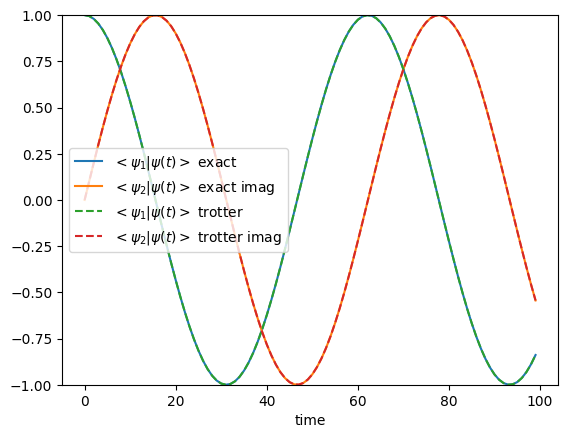

In [30]:
exact_1 = []
exact_2 = []
trotter_1 = []
trotter_2 = []
import numpy as np
for t in np.linspace(0, 10, 100):

    sparse_state = time_evolution(t)

    exact_1.append((sparse_ref1.T.conj() @ sparse_state)[0, 0].real)
    exact_2.append((sparse_ref2.T.conj() @ sparse_state)[0, 0].imag)

    sparse_state = time_evolution_trotter(t)

    trotter_1.append((sparse_ref1.T.conj() @ sparse_state)[0, 0].real)
    trotter_2.append((sparse_ref2.T.conj() @ sparse_state)[0, 0].imag)

plt.plot(exact_1, label='$<\psi_1 | \psi(t)>$ exact')
plt.plot(exact_2, label='$<\psi_2 | \psi(t)>$ exact imag')

plt.plot(trotter_1, '--', label='$<\psi_1 | \psi(t)>$ trotter')
plt.plot(trotter_2, '--', label='$<\psi_2 | \psi(t)>$ trotter imag')
plt.legend()
plt.xlabel('time')
plt.ylim(-1, 1)

(-1.0, 1.0)

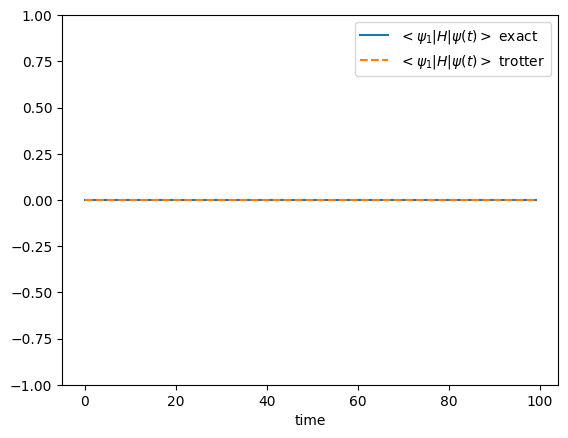

In [31]:
Hh_sparse = get_sparse_operator(ha_qubit, n_qubits=3)

exact = []
trotter = []
import numpy as np
for t in np.linspace(0, 10, 100):

    sparse_state = time_evolution(t)

    exact.append((sparse_state.T.conj() @ Hh_sparse @ sparse_state)[0, 0].real)

    sparse_state = time_evolution_trotter(t)

    trotter.append((sparse_state.T.conj() @ Hh_sparse @  sparse_state)[0, 0].real)

plt.plot(exact, label='$<\psi_1 | H | \psi(t)>$ exact')
plt.plot(trotter, '--', label='$<\psi_1 | H | \psi(t)>$ trotter')
plt.legend()
plt.xlabel('time')
plt.ylim(-1, 1)

## Exact evolution versus first-order Trotterization

The exact routine evaluates the exponential of the complete Hamiltonian. The Trotter routine instead uses

$$e^{-it\sum_j H_j} \approx \prod_j e^{-itH_j}. $$

This first-order approximation is exact only when all $H_j$ commute. The overlaps with two reference determinants show how the initial state changes in time. The energy plot compares $\langle H\rangle_t$ from exact and product-formula evolution; exact evolution conserves this expectation for a time-independent Hamiltonian.

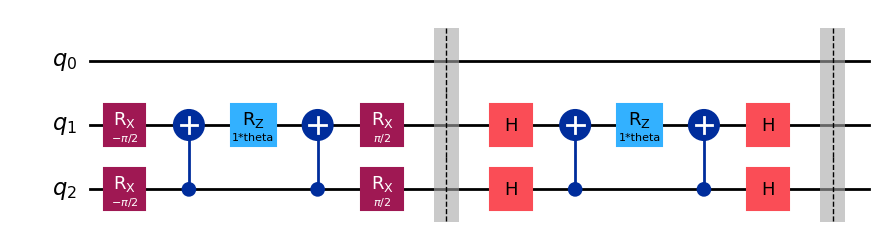

In [32]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector, Parameter

te_qubit = -1j * ha_qubit

# Define the variational parameter
theta = Parameter("theta")

# Build the ansatz
qc = QuantumCircuit(3)

i_op = 0
for op, coef in te_qubit.terms.items():

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(-np.pi / 2, [qubit])

    for qubit, pauli in op[1:]:
        qc.cx(qubit, op[0][0])

    if len(op) > 0:
        qc.rz(2*theta * coef.imag, op[0][0])

    for qubit, pauli in reversed(op[1:]):
        qc.cx(qubit, op[0][0])

    for qubit, pauli in op:
        if pauli == 'X':
            qc.h(qubit)
        elif pauli == 'Y':
            qc.rx(np.pi / 2, [qubit])

    qc.barrier()

qc.draw('mpl')

## Compiling Pauli exponentials into a circuit

Each mapped Hamiltonian term is a Pauli string. To implement $e^{-i\theta P}$, the circuit rotates X and Y factors into the Z basis, computes their parity with a CNOT ladder, applies `rz(2*theta*coefficient)` to the parity qubit, and reverses the CNOT and basis transformations.

The factor of two follows from Qiskit's convention $R_z(\phi)=e^{-i\phi Z/2}$. Concatenating the term circuits gives the same first-order product-formula structure used in the numerical comparison.

In [33]:
from qiskit.primitives import StatevectorSampler

def cost_function(params):
    energy = 0.0
    for op, coeff in ha_qubit.terms.items():

        # setup circuit
        qc_prep = QuantumCircuit(3)

        # reference
        qc_prep.x(0)
        qc_prep.x(1)
        qc_prep = qc_prep.compose(qc.assign_parameters(params))

        qc_meas = qc_prep.copy()

        # set measurement basis
        for qi, pauli in op:
            if pauli == "X":
                qc_meas.h(qi)
            if pauli == "Y":
                qc_meas.rx(np.pi / 2, qi)
                #qc_meas.sdg(qi)
                #qc_meas.h(qi)

        # add mesure
        qc_meas.measure_all()

        # Sample
        sampler = StatevectorSampler()

        result = sampler.run([qc_meas], shots=1000).result()
        counts = result[0].data.meas.get_counts()

        shots = sum(counts.values())

        # compute expected value
        for bitstring, count in counts.items():

            parity = 1
            for qi, pauli in op:
                if bitstring[::-1][qi] == "1":
                    parity *= -1

            energy += parity * count / shots * coeff

    return energy.real

cost_function([0.0])

-0.011999999999999983

(-1.0, 1.0)

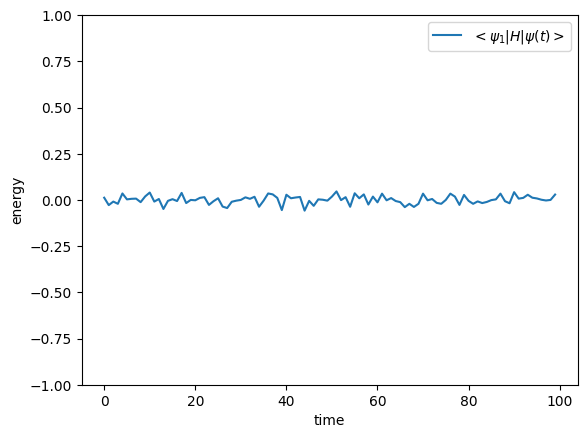

In [34]:
trotter = []
import numpy as np
for t in np.linspace(0, 10, 100):
    energy = cost_function([t])
    trotter.append(energy)

plt.plot(trotter, label='$<\psi_1 | H | \psi(t)>$')
plt.legend()
plt.xlabel('time')
plt.ylabel('energy')
plt.ylim(-1, 1)

## Estimating the evolved-state energy

The Hamiltonian has the Pauli expansion $H=\sum_k c_kP_k$. `cost_function` prepares the reference determinant, evolves it with the parameterized circuit, and measures each $P_k$ separately. The parity of each measured bit string supplies a $+1$ or $-1$ eigenvalue, giving

$$\widehat{\langle H\rangle}=\sum_k c_k\widehat{\langle P_k\rangle}. $$

Finite sampling means the plotted value is an estimator and can fluctuate around the exact expectation.

- Try with a different hamiltonian (whose energy is not zero for the |11> state
- change the initial state and observe what happens
- Why the energy is constant?
- change the reference states to analyze how is the initial state evolving


## Measuring overlaps with a Hadamard test

The final circuit introduces an ancilla in $|+\rangle$, applies a controlled version of the evolution, then measures the ancilla after a final Hadamard. This implements the Hadamard test,

$$\langle Z_{\mathrm{anc}}\rangle=\mathrm{Re}\langle\psi|U|\psi\rangle. $$

Adding the indicated ancilla phase before the controlled unitary gives access to the imaginary component, subject to the selected phase convention. Together, the two measurements determine the complex overlap between the reference state and its evolved state.

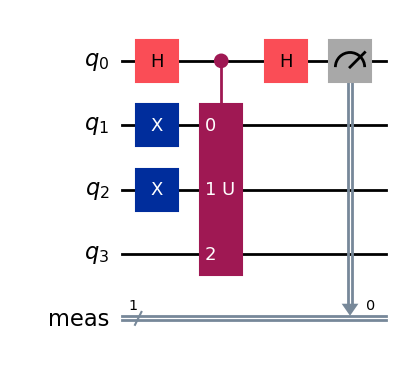

In [35]:
from qiskit import QuantumCircuit, ClassicalRegister, QuantumRegister
from qiskit.primitives import StatevectorSampler

c_reg = ClassicalRegister(1, "meas")
q = QuantumRegister(4, r'q')

def remove_barriers(qc):
    qc = qc.copy()
    qc.data = [
        instruction
        for instruction in qc.data
        if instruction.operation.name != "barrier"
    ]
    return qc

def evolution_gate(params):

    # state evolution
    evol = remove_barriers(qc)
    evol = evol.assign_parameters(params)

    # Conditional transformation |101> -> |110>
    #evol.x(1)
    #evol.x(2)

    return evol.to_gate(label="U")


# Build the ansatz
def get_hadamard_test_circuit(params, imaginary_part=False):

    qc_test = QuantumCircuit(q, c_reg)

    # reference
    qc_test.x(1)
    qc_test.x(2)

    qc_test.h(0)


    if imaginary_part:
        qc_test.s(0) # for imaginary part

    U_gate = evolution_gate(params)

    U_controlled_gate = U_gate.control(1)

    qc_test.append(U_controlled_gate, [0, 1, 2, 3])
    qc_test.h(0)

    qc_test.measure(q[0], c_reg)

    return qc_test

get_hadamard_test_circuit([0.1]).draw('mpl')



1.0
0.8641
0.49774
-0.01072
-0.50194
-0.87212
-0.99994
-0.85726
-0.48106
0.0217
0.52366
0.88186
0.9995
0.84966
0.46936
-0.0428
-0.53484
-0.88886
-0.99864
-0.83626


(-1.0, 1.0)

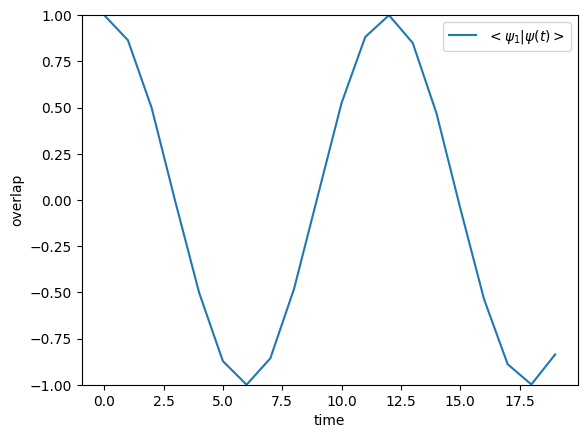

In [36]:
def cost_function_overlap(params):

    sampler = StatevectorSampler()

    n_shots = 100000

    # real part
    qc_test = get_hadamard_test_circuit(params, imaginary_part=False)
    result = sampler.run([qc_test], shots=n_shots).result()
    counts = result[0].data.meas.get_counts()
    overlap_real = (counts.get('0', 0) - counts.get('1', 0)) / n_shots

    # imaginary part
    #qc_test = get_hadamard_test_circuit(params, imaginary=True)
    #result = sampler.run([qc_test], shots=n_shots).result()
    #counts = result[0].data.meas.get_counts()
    #overlap_imag = (counts.get('0', 0) - counts.get('1', 0)) / n_shots

    print(overlap_real)
    return overlap_real

overlaps = []
import numpy as np
for t in np.linspace(0, 10, 20):
    overlaps.append(cost_function_overlap([t]))

plt.plot(overlaps, label='$<\psi_1 | \psi(t)>$')
plt.legend()
plt.xlabel('time')
plt.ylabel('overlap')
plt.ylim(-1, 1)

## Exercises

- Change the circuit to compute the overlap <110 | U | 101>